# Case Study 02 — Do Higher Earners Default Less?

**Conditional probability · two-sample tests (Student, Welch, Mann-Whitney) · chi-square test of independence ·
effect sizes · risk ratios · from statistical evidence to a policy decision**

| | |
|---|---|
| **Domain** | Retail lending: credit risk policy |
| **Stakeholder** | Head of Risk Policy |
| **Difficulty** | Beginner |
| **Importance** | 🔴 MUST GO THROUGH |
| **Builds on** | Case 01 (descriptive statistics, CIs, hypothesis testing) |
| **Data** | 6,000 personal loans disbursed in 2024 with 12-month performance |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`.

**What you will learn**

1. How to read a contingency table as **joint, marginal and conditional probabilities**, and why
   P(default | low income) ≠ P(low income | default).
2. How to compare a skewed variable between two groups, and why **Student's t, Welch's t, Mann-Whitney and a
   t-test on logs answer four different questions**.
3. How to test whether default depends on an income band (**chi-square test of independence**), and how to
   read expected counts, residuals and **Cramér's V**.
4. How to report **effect sizes** a business understands: risk ratio, risk difference, "typical income is X%
   lower".
5. Why **a strong, highly significant association can still be a bad basis for a policy**.

## Section 1 — Business context

You are a data scientist supporting the **Risk Policy** team of a retail lender. The current personal-loan policy
requires a minimum verified monthly income of **₹20,000**. The Head of Risk Policy writes:

> *"Our collections team keeps telling us that low-income customers are the problem. I'd like to raise the
> minimum income to ₹30,000 from next quarter. Before I take this to the Credit Committee, can you confirm from
> data that higher earners default less, tell me by how much, and tell me whether raising the floor is worth it?"*

You receive a performance file: **6,000 personal loans disbursed in 2024**, each observed for 12 months.

- **Default** = 90+ days past due at any time within 12 months (industry-standard definition).
- Every loan in the file was **approved under the current policy** (income ≥ ₹20,000). We see no performance for
  declined applicants. This matters later.

Notice the shape of the request. It contains a **belief** ("low earners default more"), a **quantity** ("by how
much") and a **decision** ("is the floor worth it?"). These need different tools, and the third does not follow
automatically from the first two.

## Section 2 — Business questions

1. Is the default rate actually higher for lower-income customers?
2. How different are the incomes of customers who defaulted and customers who repaid?
3. Is the relationship between income band and default real, or could it be chance?
4. How big is the effect, in terms a Credit Committee understands?
5. Would raising the income floor from ₹20,000 to ₹30,000 create value: how many defaults avoided, how many good
   customers lost, and what is the net financial effect?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | Do low earners default more? | Is P(default \| income band) different across bands? | Conditional probabilities from a contingency table |
| 2 | How different are incomes? | Does the income distribution of defaulters differ from that of non-defaulters? Which summary differs (mean, typical value, ranks)? | Welch t-test (means), t-test on log income (geometric means), Mann-Whitney U (ranks / stochastic ordering) |
| 3 | Real or chance? | Are income band and default status independent? | **Chi-square test of independence** (+ trend test) |
| 4 | How big? | Effect sizes | Risk ratio and risk difference with CIs, Cramér's V, Cohen's d, ratio of geometric means, common-language effect size |
| 5 | Is the floor worth it? | Expected financial impact of excluding loans below ₹30k, with uncertainty | Counterfactual policy simulation on the observed book + bootstrap CI + sensitivity analysis |

> **Exploratory or confirmatory?** The belief "low earners default more" was stated *before* we looked at the
> data, and the ₹30,000 threshold was proposed by the business, not chosen by us after seeing the data. So
> questions 1–3 are **confirmatory** tests of a pre-specified hypothesis. Had we scanned many thresholds and
> reported the one with the biggest gap, the p-values would be optimistic (see Case 19).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.contingency_tables import Table, Table2x2

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_money, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, thousands_formatter, COLORS, PRIMARY, HIGHLIGHT, INK, INK_MUTED
from statistical_tests import describe_numeric, proportion_ci, bootstrap_ci, cohens_d

CASE_DIR = ROOT / "case_studies" / "02_income_and_default"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
rng = rng_for_case(202)

CURRENT_FLOOR = 20_000
PROPOSED_FLOOR = 30_000
k_fmt = thousands_formatter("₹", "k", 1e3, 0)

## Section 4 — Load the data

In [2]:
raw = pd.read_csv(PATHS["data"] / "loan_performance_2024.csv")
print(f"{raw.shape[0]:,} rows, {raw.shape[1]} columns")
display(raw.head())
raw.dtypes.to_frame("dtype").T

6,000 rows, 8 columns


,loan_id,city_tier,employment_type,monthly_income,credit_score,loan_amount,dti,defaulted
0,PL24200000,Tier-3,Salaried,"34,300.000",787,180000,0.536,0
1,PL24200001,Tier-3,Salaried,"49,300.000",707,140000,0.484,0
2,PL24200002,Metro,Salaried,"21,900.000",655,60000,0.384,0
3,PL24200003,Tier-2,Salaried,"56,900.000",753,120000,0.087,1
4,PL24200004,Metro,Salaried,"185,200.000",815,310000,0.077,0


,loan_id,city_tier,employment_type,monthly_income,credit_score,loan_amount,dti,defaulted
dtype,str,str,str,float64,int64,int64,float64,int64


| Column | Type | Meaning |
|---|---|---|
| `loan_id` | ID | Loan account |
| `city_tier` | Categorical | Metro / Tier-2 / Tier-3 |
| `employment_type` | Categorical | Salaried / Self-employed |
| `monthly_income` | Numeric (₹) | Verified monthly income at application. **The explanatory variable of interest.** |
| `credit_score` | Numeric | Bureau score at application |
| `loan_amount` | Numeric (₹) | Disbursed amount |
| `dti` | Ratio | Debt-to-income at application |
| `defaulted` | Binary | **Target**: 1 = 90+ DPD within 12 months |

The target is **binary**, so its mean is a proportion (the default rate). Our main explanatory variable,
income, is **continuous and right-skewed** (Case 01). We will also turn it into **bands**, because policy is
written in bands ("minimum ₹30,000").

## Section 5 — Data quality

In [3]:
print(f"Duplicate rows: {raw.duplicated().sum()},  duplicate loan_ids: {raw['loan_id'].duplicated().sum()}")
print(f"Missing values:\n{raw.isna().sum()[raw.isna().sum() > 0]}")
print(f"\nIncome = 0: {(raw['monthly_income'] == 0).sum()} rows")
print(f"Income below the policy floor (0 < income < {CURRENT_FLOOR:,}): "
      f"{((raw['monthly_income'] > 0) & (raw['monthly_income'] < CURRENT_FLOOR)).sum()} rows")
print(f"Default flag values: {sorted(raw['defaulted'].unique())}")
print(f"Credit score range: {raw['credit_score'].min()}–{raw['credit_score'].max()},  DTI range: {raw['dti'].min()}–{raw['dti'].max()}")

# Is missing/zero income related to the outcome? (if yes, excluding these rows could bias results)
bad_income = raw["monthly_income"].isna() | raw["monthly_income"].eq(0)
raw.groupby(bad_income.rename("income_missing_or_zero"))["defaulted"].agg(["size", "mean"])

Duplicate rows: 0,  duplicate loan_ids: 0


Missing values:
monthly_income    52
dtype: int64

Income = 0: 7 rows
Income below the policy floor (0 < income < 20,000): 0 rows
Default flag values: [np.int64(0), np.int64(1)]
Credit score range: 547–900,  DTI range: 0.03–0.8


,size,mean
income_missing_or_zero,,
False,5941,0.069
True,59,0.085


- **Income = 0** on 7 loans cannot be true: every loan was approved with income ≥ ₹20,000. This is the system's
  code for "not captured". Treating 0 as a real income would create seven fictional ultra-low earners.
  We treat it as **missing**.
- **52 more** loans have blank income. Together, 59 loans (1%) lack income.
- Their default rate is similar to the rest of the file. With only 59 loans that comparison is imprecise, but
  there is no sign that dropping them distorts the comparison. We **exclude them** from income analyses and note
  it as a limitation.
- No duplicates, no out-of-range scores or DTIs, and the outcome is cleanly 0/1.

In [4]:
loans = raw[~bad_income].copy()
loans["income_band"] = pd.cut(loans["monthly_income"], [0, 25_000, 40_000, 60_000, 100_000, np.inf],
                              labels=["₹20–25k", "₹25–40k", "₹40–60k", "₹60–100k", "≥ ₹100k"], right=False)
loans["below_30k"] = loans["monthly_income"] < PROPOSED_FLOOR
loans["outcome"] = loans["defaulted"].map({0: "Repaid", 1: "Defaulted"})
print(f"Analysis dataset: {len(loans):,} loans, {loans['defaulted'].sum()} defaults ({loans['defaulted'].mean():.2%})")

Analysis dataset: 5,941 loans, 407 defaults (6.85%)


## Section 6 — Descriptive statistics

### 6.1 Income by outcome

In [5]:
by_outcome = pd.DataFrame({k: describe_numeric(g["monthly_income"]) for k, g in loans.groupby("outcome")}).T
by_outcome["geometric_mean"] = loans.groupby("outcome")["monthly_income"].apply(stats.gmean)
save_table(by_outcome, "income_by_outcome", PATHS["tables"])
by_outcome[["n", "mean", "geometric_mean", "median", "std", "p25", "p75", "iqr", "cv", "skewness"]]

,n,mean,geometric_mean,median,std,p25,p75,iqr,cv,skewness
Defaulted,407.000,"41,773.710","36,923.977","33,200.000","24,177.446","24,900.000","51,650.000","26,750.000",0.579,2.187
Repaid,"5,534.000","59,135.652","49,947.898","48,000.000","39,619.261","32,000.000","72,400.000","40,400.000",0.670,2.444


Things a careful analyst notices before any test:

- **Group sizes are very unequal:** about 400 defaulters vs 5,500 repayers. That is typical of credit data (the
  outcome is rare) and matters for method choice.
- **Spreads are very different:** repayers' income SD (≈ ₹40k) is much larger than defaulters' (≈ ₹24k),
  because high earners, who create the long tail, rarely default. **Unequal variances** will matter for
  the t-test.
- **Both groups are right-skewed**, so mean ≠ median. Defaulters' median income is about ₹33k vs ₹48k for
  repayers.

### 6.2 Default rate by income band: a contingency table

In [6]:
counts = pd.crosstab(loans["income_band"], loans["outcome"], margins=True, margins_name="Total")[["Defaulted", "Repaid", "Total"]]
counts

outcome,Defaulted,Repaid,Total
income_band,,,
₹20–25k,104,652,756
₹25–40k,147,1472,1619
₹40–60k,90,1421,1511
₹60–100k,52,1309,1361
≥ ₹100k,14,680,694
Total,407,5534,5941


### 6.3 Reading the table as probabilities

A contingency table can be read in three different ways. Business conversations constantly mix them up.

| Type | Notation | Question it answers | Computed as |
|---|---|---|---|
| **Joint** | P(band **and** default) | "What share of *all loans* are low-income defaulters?" | cell ÷ grand total |
| **Marginal** | P(default), P(band) | "What share of all loans default?" / "...are low-income?" | row or column total ÷ grand total |
| **Conditional** | P(default **given** band) | "Among low-income loans, what share default?" | cell ÷ **row** total |
| **Inverse conditional** | P(band **given** default) | "Among defaulters, what share were low-income?" | cell ÷ **column** total |

In [7]:
N = len(loans)
ct = pd.crosstab(loans["income_band"], loans["defaulted"])
joint = ct / N
p_band = ct.sum(axis=1) / N                      # marginal P(band)
p_default = ct[1].sum() / N                      # marginal P(default)
p_def_given_band = ct[1] / ct.sum(axis=1)        # conditional P(default | band)
p_band_given_def = ct[1] / ct[1].sum()           # inverse conditional P(band | default)

prob = pd.DataFrame({
    "P(band)": p_band,
    "P(band and default)": joint[1],
    "P(default | band)": p_def_given_band,
    "P(band | default)": p_band_given_def,
    "P(band) x P(default)  [if independent]": p_band * p_default,
})
save_table(prob, "probability_table", PATHS["tables"])
print(f"Marginal P(default) = {p_default:.2%}")
prob.style.format("{:.2%}")

Marginal P(default) = 6.85%


,P(band),P(band and default),P(default | band),P(band | default),P(band) x P(default) [if independent]
income_band,,,,,
₹20–25k,12.73%,1.75%,13.76%,25.55%,0.87%
₹25–40k,27.25%,2.47%,9.08%,36.12%,1.87%
₹40–60k,25.43%,1.51%,5.96%,22.11%,1.74%
₹60–100k,22.91%,0.88%,3.82%,12.78%,1.57%
≥ ₹100k,11.68%,0.24%,2.02%,3.44%,0.80%


How to read it:

- **Conditional probability, P(default | band):** the default rate falls steadily with income, from about **13.8%**
  in the ₹20–25k band to about **2.0%** at ≥ ₹100k. This is the quantity that answers the business question.
- **Independence check:** if income and default were **independent**, the joint probability would equal the product
  of the marginals, P(band and default) = P(band) × P(default). Equivalently, P(default | band) would be the same
  6.9% in every band. The last column shows what independence would predict. The low bands have far more joint
  probability than that, and the high bands far less. Income band and default look **dependent**. Section 10
  tests whether this could be chance.

In [8]:
low = loans["below_30k"]
p_def_given_low = loans.loc[low, "defaulted"].mean()
p_low_given_def = low[loans["defaulted"] == 1].mean()
p_low = low.mean()
print(f"P(default | income < ₹30k)  = {p_def_given_low:.1%}   <- risk of a low-income customer")
print(f"P(income < ₹30k | default)  = {p_low_given_def:.1%}   <- share of defaulters who are low-income")
print(f"P(income < ₹30k)            = {p_low:.1%}")
print(f"P(default)                  = {p_default:.1%}")
print(f"Bayes check: P(low|def) = P(def|low) x P(low) / P(def) = "
      f"{p_def_given_low:.4f} x {p_low:.4f} / {p_default:.4f} = {p_def_given_low * p_low / p_default:.1%}")

P(default | income < ₹30k)  = 13.0%   <- risk of a low-income customer
P(income < ₹30k | default)  = 43.0%   <- share of defaulters who are low-income
P(income < ₹30k)            = 22.7%
P(default)                  = 6.9%
Bayes check: P(low|def) = P(def|low) x P(low) / P(def) = 0.1300 x 0.2266 / 0.0685 = 43.0%


**The confusion of the inverse.** "43% of our defaulters earn under ₹30k" is often heard as "low earners have a
43% chance of defaulting". The real figure is **13%**. The two numbers are linked by Bayes' theorem (checked
above), and they differ because low earners are only about 23% of the book while defaults are only about 7%.

Both numbers are true; they answer different questions:

- *Collections* sees **P(low income | default)**: "most of my problem accounts are low-income", which is
  true and is where the belief came from.
- *Underwriting* must decide on **P(default | low income)**: "if I approve a low-income applicant, how likely
  are they to default?" The answer is 13%, so **87% of low-income customers repay**.

Case 24 builds on this (Bayes' theorem and base rates).

## Section 7 — Visualisation

### Figure 1 — Income distributions of defaulters and repayers

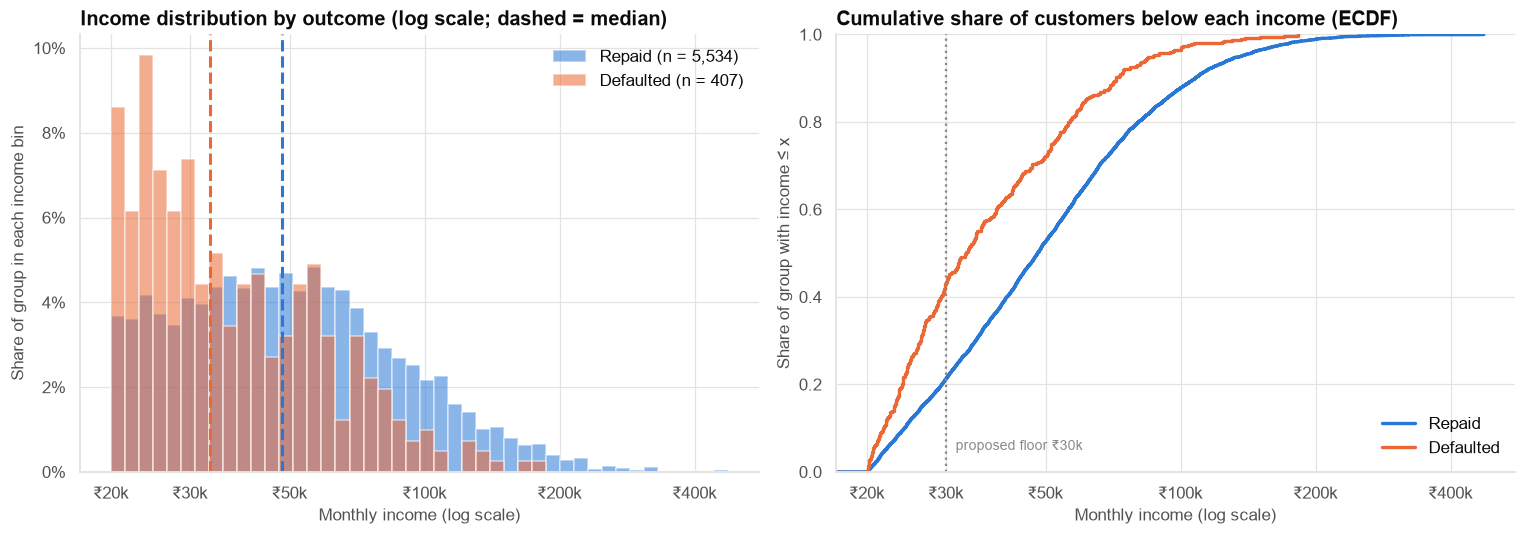

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bins = np.logspace(np.log10(20_000), np.log10(loans["monthly_income"].max()), 45)
for outcome, color in [("Repaid", PRIMARY), ("Defaulted", HIGHLIGHT)]:
    x = loans.loc[loans["outcome"] == outcome, "monthly_income"]
    axes[0].hist(x, bins=bins, weights=np.full(len(x), 1 / len(x)), alpha=0.55, color=color, label=f"{outcome} (n = {len(x):,})")
    axes[0].axvline(x.median(), color=color, lw=2, ls="--")
    sns.ecdfplot(x, ax=axes[1], color=color, lw=2.2, label=outcome)
axes[0].set_xscale("log")
axes[0].xaxis.set_major_formatter(k_fmt)
axes[0].xaxis.set_minor_formatter(plt.NullFormatter())
axes[0].set_xticks([20_000, 30_000, 50_000, 100_000, 200_000, 400_000])
axes[0].set(title="Income distribution by outcome (log scale; dashed = median)",
            xlabel="Monthly income (log scale)", ylabel="Share of group in each income bin")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].legend(loc="upper right")
axes[1].axvline(PROPOSED_FLOOR, color=INK_MUTED, ls=":", lw=1.5)
axes[1].text(PROPOSED_FLOOR * 1.05, 0.05, "proposed floor ₹30k", color=INK_MUTED, fontsize=9)
axes[1].set_xscale("log")
axes[1].xaxis.set_major_formatter(k_fmt)
axes[1].xaxis.set_minor_formatter(plt.NullFormatter())
axes[1].set_xticks([20_000, 30_000, 50_000, 100_000, 200_000, 400_000])
axes[1].set(title="Cumulative share of customers below each income (ECDF)",
            xlabel="Monthly income (log scale)", ylabel="Share of group with income ≤ x")
axes[1].legend(loc="lower right")
fig.tight_layout()
save_fig(fig, "fig01_income_by_outcome", PATHS["figures"])
plt.show()

**Observation.** Defaulters' incomes are shifted to the left. Their ECDF rises faster: about 43% of defaulters
earn under ₹30k, compared with about 21% of repayers. The two distributions still **overlap heavily**: plenty of
defaulters earn well, and most low earners repay.

**Interpretation.** The difference is a *shift* plus a *shape* difference: the repayers have a much longer right
tail. On the log scale the shapes look roughly similar, which tells us that comparing **log income** (ratios) is
natural here.

**Business implication.** Income separates the groups somewhat, but far from perfectly. Any income cut-off will
exclude many good customers along with the bad ones.

**Caveat.** This is the **approved** population. We never see how customers below ₹20k would have
performed, so we cannot extrapolate below the current floor.

### Figure 2 — Default rate by income band

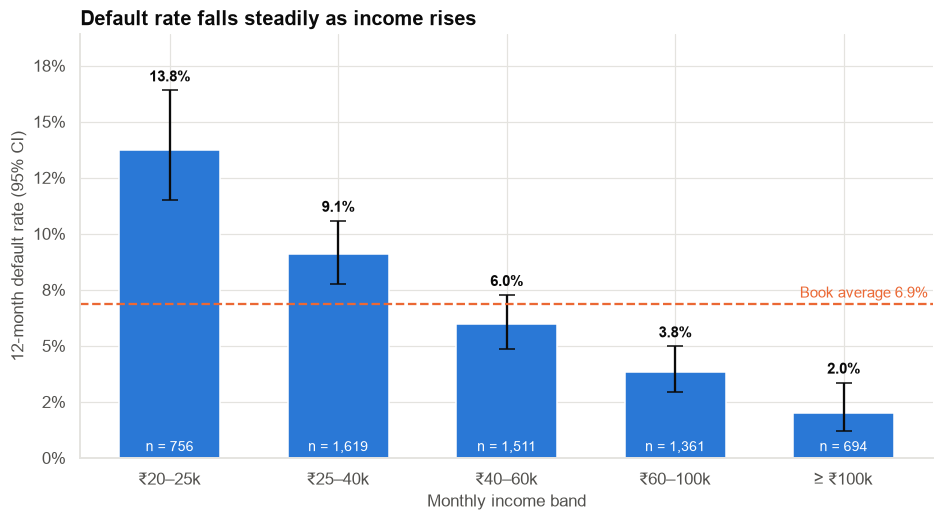

In [10]:
band_stats = loans.groupby("income_band", observed=True)["defaulted"].agg(loans="size", defaults="sum")
cis = [proportion_ci(k, n) for k, n in zip(band_stats["defaults"], band_stats["loans"])]
band_stats["default_rate"] = band_stats["defaults"] / band_stats["loans"]
band_stats["ci_low"] = [c["lower"] for c in cis]
band_stats["ci_high"] = [c["upper"] for c in cis]
save_table(band_stats, "default_rate_by_band", PATHS["tables"])

fig, ax = plt.subplots(figsize=(10, 5))
xpos = np.arange(len(band_stats))
ax.bar(xpos, band_stats["default_rate"], color=PRIMARY, width=0.6)
ax.errorbar(xpos, band_stats["default_rate"],
            yerr=[band_stats["default_rate"] - band_stats["ci_low"], band_stats["ci_high"] - band_stats["default_rate"]],
            fmt="none", ecolor=INK, capsize=5, lw=1.5)
ax.axhline(p_default, color=HIGHLIGHT, ls="--", lw=1.5)
ax.text(len(band_stats) - 0.5, p_default + 0.003, f"Book average {p_default:.1%}", color=HIGHLIGHT, ha="right", fontsize=10)
for x, (_, r) in zip(xpos, band_stats.iterrows()):
    ax.text(x, r["ci_high"] + 0.004, f"{r['default_rate']:.1%}", ha="center", fontsize=10, fontweight="bold")
    ax.text(x, 0.003, f"n = {int(r['loans']):,}", ha="center", fontsize=9, color="white")
ax.set_xticks(xpos, band_stats.index)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylim(0, band_stats["ci_high"].max() + 0.025)
ax.set(title="Default rate falls steadily as income rises", xlabel="Monthly income band",
       ylabel="12-month default rate (95% CI)")
save_fig(fig, "fig02_default_rate_by_band", PATHS["figures"])
plt.show()

**Observation.** The default rate falls in every step, from about 13.8% to about 2.0%. The intervals for adjacent
bands barely overlap, and the lowest and highest bands are far apart.

**Interpretation.** A **monotonic** (steadily decreasing) pattern is more convincing than one big gap between two
groups. It is the kind of **dose-response** pattern you expect if the association is real. It does not
show causation.

**Business implication.** Income carries genuine information about risk. The question is whether a hard
floor is the best way to use it.

**Caveat.** Income is correlated with credit score and DTI (Section 15). Part of the "income effect" in this
chart could be a score or affordability effect. This chart shows the **total association**, not the effect of
income alone.

## Section 8 — Statistical method selection

### Question 2: do the incomes of defaulters and repayers differ?

```text
Outcome variable : monthly income, continuous, strongly right-skewed, long right tail
Groups           : two (defaulted / repaid), independent (different customers)
Group sizes      : very unequal (≈ 400 vs ≈ 5,500)
Spreads          : very unequal (SD ≈ ₹24k vs ≈ ₹40k)
```

The key insight: **"do incomes differ?" is not one question.** Each candidate method answers a different one
(it has a different *estimand*):

| Method | Estimand (what it compares) | Assumptions | Verdict |
|---|---|---|---|
| Student's t-test | Difference in **means** | Independence; approx. normal sample means (CLT); **equal variances** | ❌ The equal-variance assumption clearly fails, and with unequal n this gives the **wrong standard error**. Shown for contrast. |
| **Welch's t-test** | Difference in **means** | Independence; approx. normal sample means | ✅ **Default choice for comparing means.** Does not assume equal variances, and loses almost nothing when they are equal. |
| **t-test on log(income)** | Ratio of **geometric means** ("typical" income, in % terms) | Same as Welch, on the log scale | ✅ Natural for money: "defaulters' typical income is X% lower". |
| **Mann-Whitney U** | P(random defaulter earns more than random repayer): **stochastic ordering / ranks** | Independence; ordinal or continuous data | ✅ Robust to the long tail; gives an intuitive effect size. **It is not a test of medians** unless the two shapes are identical. |
| Bootstrap difference in medians | Difference in **medians** | Independence; enough data | ✅ Used as a descriptive check (Case 23 goes deeper). |

> **Avoid the shortcut "data not normal → Mann-Whitney".** With ~400 and ~5,500 observations, the CLT makes the
> t-test valid for comparing means even though income is skewed. The real choice is **which estimand answers the
> business question**. For a policy about *typical* customers, the log-scale comparison and the rank-based
> comparison are more relevant than the raw mean, which a few very rich repayers inflate. We report all three
> and check that they tell a consistent story.

### Question 3: is default independent of income band?

```text
Variables : income band (5 ordered categories) × default (2 categories)
Data      : counts in a 5 × 2 table; every expected count is far above 5
```

| Method | Verdict |
|---|---|
| **Chi-square test of independence** | ✅ Standard test for "are two categorical variables related?". Expected counts are all large. |
| Fisher's exact test | ❌ Not needed: designed for small expected counts (Case 03 uses it). |
| Chi-square *trend* (linear-by-linear) test | ✅ Supplementary. The plain chi-square ignores that the bands are **ordered**. A trend test uses the order and is more powerful for a steady decline. |
| Logistic regression on income | Deferred to Cases 11 and 27, where we also control for score and DTI. |

### Question 4: effect size for the ₹30k threshold

A 2 × 2 table (below ₹30k vs above, default vs repaid). We report the **risk difference** (percentage points),
the **risk ratio** (how many times riskier), and the **odds ratio** (needed later for logistic regression), each
with a CI.

## Section 9 — Assumption checking

In [11]:
inc_def = loans.loc[loans["defaulted"] == 1, "monthly_income"]
inc_rep = loans.loc[loans["defaulted"] == 0, "monthly_income"]

lev = stats.levene(inc_def, inc_rep, center="median")      # Brown-Forsythe version: robust to skew
print(f"Variance ratio (repaid / defaulted) = {inc_rep.var() / inc_def.var():.2f}")
print(f"Levene (Brown-Forsythe) test of equal variances: W = {lev.statistic:.1f}, p = {fmt_p(lev.pvalue)}")
print(f"Group sizes: defaulted {len(inc_def)}, repaid {len(inc_rep)}")
print(f"Skewness: defaulted {stats.skew(inc_def):.2f}, repaid {stats.skew(inc_rep):.2f}")
print(f"Skewness of log income: defaulted {stats.skew(np.log(inc_def)):.2f}, repaid {stats.skew(np.log(inc_rep)):.2f}")

Variance ratio (repaid / defaulted) = 2.69
Levene (Brown-Forsythe) test of equal variances: W = 41.3, p = < 0.001
Group sizes: defaulted 407, repaid 5534
Skewness: defaulted 2.18, repaid 2.44
Skewness of log income: defaulted 0.78, repaid 0.46


| Assumption | Evidence | Decision |
|---|---|---|
| **Independence** within and between groups | Different customers; one loan per customer in this file | ✅ |
| **Approximately normal sampling distribution of each mean** | n = 407 and 5,534. Skewness ≈ 2.2–2.4 is easily handled by the CLT at these sizes (Case 01 showed n = 200 was already enough for a similar variable). | ✅ for mean-based tests |
| **Equal variances** (Student only) | Variance ratio ≈ 2.7; Brown-Forsythe p < 0.001 | ❌ **Student's t is inappropriate. Use Welch.** |
| Log scale for the geometric-mean test | Log income is far less skewed (≈ 0.5–0.8) in both groups | ✅ |
| Mann-Whitney: independent observations; continuous/ordinal outcome | ✅. Ties (incomes are rounded to ₹100) are handled by scipy's tie correction. | ✅ |
| Chi-square: independent observations, expected counts ≥ 5 | Checked in Section 10 (minimum expected count ≈ 48) | ✅ |

**Why unequal variances plus unequal sizes is the dangerous combination for Student's t.** Student's t pools the
two variances, weighting each by its group size. Here the pooled variance is dominated by the large repaid group.
The true standard error of the difference, however, is dominated by the **small** group's uncertainty. When the
larger group also has the larger variance, as here, Student's t *overstates* the SE and becomes too
conservative. When the smaller group has the larger variance, Student's t *understates* the SE and gives
**too many false positives**. Welch avoids both problems, so **use Welch by default**.

## Section 10 — Analysis

### 10.1 Difference in mean income: Welch's t-test by hand

In [12]:
m1, m2 = inc_def.mean(), inc_rep.mean()
v1, v2 = inc_def.var(ddof=1), inc_rep.var(ddof=1)
n1, n2 = len(inc_def), len(inc_rep)

se_welch = np.sqrt(v1 / n1 + v2 / n2)
t_welch = (m1 - m2) / se_welch
df_welch = (v1 / n1 + v2 / n2) ** 2 / ((v1 / n1) ** 2 / (n1 - 1) + (v2 / n2) ** 2 / (n2 - 1))   # Welch-Satterthwaite
p_welch = 2 * stats.t.sf(abs(t_welch), df_welch)
t_crit = stats.t.ppf(0.975, df_welch)
ci_welch = (m1 - m2 - t_crit * se_welch, m1 - m2 + t_crit * se_welch)

print(f"Mean income: defaulted {fmt_money(m1)}, repaid {fmt_money(m2)}, difference {fmt_money(m1 - m2)}")
print(f"SE = sqrt(s1²/n1 + s2²/n2) = {fmt_money(se_welch)}")
print(f"t = {t_welch:.2f}, Welch df = {df_welch:.0f}, p = {p_welch:.1e}")
print(f"95% CI for the difference in means: [{fmt_money(ci_welch[0])}, {fmt_money(ci_welch[1])}]")
check = stats.ttest_ind(inc_def, inc_rep, equal_var=False)
print(f"scipy Welch check: t = {check.statistic:.2f}, p = {check.pvalue:.1e}")

student = stats.ttest_ind(inc_def, inc_rep, equal_var=True)
sp = np.sqrt(((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2))
se_student = sp * np.sqrt(1 / n1 + 1 / n2)
print(f"\nFor contrast, Student's t (pooled variance): t = {student.statistic:.2f}, SE = {fmt_money(se_student)} "
      f"(vs Welch SE {fmt_money(se_welch)})")
d_effect = cohens_d(inc_def, inc_rep)
print(f"Cohen's d = {d_effect:.2f}")

Mean income: defaulted ₹41,774, repaid ₹59,136, difference ₹-17,362
SE = sqrt(s1²/n1 + s2²/n2) = ₹1,311
t = -13.24, Welch df = 581, p = 3.8e-35
95% CI for the difference in means: [₹-19,938, ₹-14,786]
scipy Welch check: t = -13.24, p = 3.8e-35

For contrast, Student's t (pooled variance): t = -8.72, SE = ₹1,991 (vs Welch SE ₹1,311)
Cohen's d = -0.45


Both tests reject equality of means overwhelmingly. Notice, though, that **Student's SE is about 50% larger
than Welch's**, which is the problem described above. In other data the error goes the other way, and Student's
t would declare a difference that is not there.

The **Welch-Satterthwaite degrees of freedom** (≈ 580, not 5,939) reflect that the uncertainty comes mainly from the
smaller group. The test effectively has the precision of a few hundred observations, not six thousand.

### 10.2 Typical income: t-test on log income (ratio of geometric means)

In [13]:
log_test = stats.ttest_ind(np.log(inc_def), np.log(inc_rep), equal_var=False)
log_ci = log_test.confidence_interval()
ratio = np.exp(np.log(inc_def).mean() - np.log(inc_rep).mean())
ratio_ci = (np.exp(log_ci.low), np.exp(log_ci.high))
print(f"Geometric mean income: defaulted {fmt_money(stats.gmean(inc_def))}, repaid {fmt_money(stats.gmean(inc_rep))}")
print(f"Ratio defaulted / repaid = {ratio:.3f}, 95% CI [{ratio_ci[0]:.3f}, {ratio_ci[1]:.3f}]")
print(f"=> defaulters' typical income is {1 - ratio:.0%} lower (95% CI {1 - ratio_ci[1]:.0%} to {1 - ratio_ci[0]:.0%})")
print(f"Welch t on logs = {log_test.statistic:.2f}, p = {log_test.pvalue:.1e}")

Geometric mean income: defaulted ₹36,924, repaid ₹49,948
Ratio defaulted / repaid = 0.739, 95% CI [0.705, 0.776]
=> defaulters' typical income is 26% lower (95% CI 22% to 30%)
Welch t on logs = -12.33, p = 1.2e-30


**Why logs?** On the log scale, a difference of means becomes a **ratio** after back-transforming
(exp(mean log a − mean log b) = geometric mean a ÷ geometric mean b). Ratios are how people think about income
("20% less") and how lenders set policy ("income at least 3× the EMI"). The log transform also tames the long
tail, so a few very high earners no longer dominate the comparison.

### 10.3 Mann-Whitney U: rank-based comparison

In [14]:
mw = stats.mannwhitneyu(inc_def, inc_rep, alternative="two-sided")
cles = mw.statistic / (n1 * n2)                  # P(defaulter income > repayer income) + 0.5 * P(tie)
rank_biserial = 2 * cles - 1
print(f"U = {mw.statistic:,.0f}, p = {mw.pvalue:.1e}")
print(f"Common-language effect size: P(a random defaulter earns MORE than a random repayer) = {cles:.2f}")
print(f"Rank-biserial correlation = {rank_biserial:.2f}  (0 = no difference, -1 = every defaulter earns less)")

# Bootstrap the difference in medians: resample each group independently, recompute, repeat.
boot = np.array([np.median(rng.choice(inc_def.to_numpy(), n1)) - np.median(rng.choice(inc_rep.to_numpy(), n2))
                 for _ in range(5_000)])
med_ci = np.quantile(boot, [0.025, 0.975])
print(f"\nDifference in medians: {fmt_money(inc_def.median() - inc_rep.median())}, "
      f"95% bootstrap CI [{fmt_money(med_ci[0])}, {fmt_money(med_ci[1])}]")

U = 766,414, p = 4.6e-27
Common-language effect size: P(a random defaulter earns MORE than a random repayer) = 0.34
Rank-biserial correlation = -0.32  (0 = no difference, -1 = every defaulter earns less)



Difference in medians: ₹-14,800, 95% bootstrap CI [₹-17,400, ₹-12,400]


**Common-language effect size:** if you pick one defaulter and one repayer at random, the defaulter has the
higher income only about **34%** of the time (50% would mean no difference). That is a clear but far from
decisive separation. This "probability of superiority" is often the easiest effect size to explain to
non-statisticians.

**Mann-Whitney is not a "test of medians".** It compares the whole distributions through ranks. It equals a
comparison of medians only when the two distributions have the same shape and differ by a shift. Here the shapes
differ (different spreads), so we report the median difference separately, with a bootstrap CI.

### 10.4 Chi-square test of independence: income band × default

In [15]:
observed = pd.crosstab(loans["income_band"], loans["defaulted"])
row_tot, col_tot = observed.sum(axis=1), observed.sum(axis=0)
expected = np.outer(row_tot, col_tot) / N                  # E_ij = row_i total × col_j total / N
expected = pd.DataFrame(expected, index=observed.index, columns=observed.columns)
contrib = (observed - expected) ** 2 / expected            # each cell's contribution to chi-square
chi2_stat = contrib.to_numpy().sum()
dof = (observed.shape[0] - 1) * (observed.shape[1] - 1)
p_chi2 = stats.chi2.sf(chi2_stat, dof)
crit_chi2 = stats.chi2.ppf(0.95, dof)
cramers_v = np.sqrt(chi2_stat / (N * (min(observed.shape) - 1)))
std_resid = Table(observed.to_numpy()).standardized_resids

summary = pd.concat({"observed": observed, "expected": expected.round(1), "contribution": contrib.round(1),
                     "std_residual": pd.DataFrame(std_resid, index=observed.index, columns=observed.columns).round(1)},
                    axis=1)
display(summary)
print(f"Chi-square = {chi2_stat:.1f}, df = {dof}, critical value (5%) = {crit_chi2:.2f}, p = {p_chi2:.1e}")
print(f"Minimum expected count = {expected.to_numpy().min():.0f}")
print(f"Cramér's V = {cramers_v:.3f}")
chk = stats.chi2_contingency(observed, correction=False)
print(f"scipy check: chi2 = {chk.statistic:.1f}, p = {chk.pvalue:.1e}")

trend = Table(observed.to_numpy()).test_ordinal_association()
print(f"Linear-by-linear trend test: z = {trend.zscore:.2f}, p = {trend.pvalue:.1e}")

observed       expected         contribution        std_residual  \
defaulted          0    1         0       1            0      1            0   
income_band                                                                    
₹20–25k          652  104   704.200  51.800        3.900 52.600       -8.000   
₹25–40k         1472  147 1,508.100 110.900        0.900 11.700       -4.200   
₹40–60k         1421   90 1,407.500 103.500        0.100  1.800        1.600   
₹60–100k        1309   52 1,267.800  93.200        1.300 18.200        5.000   
≥ ₹100k          680   14   646.500  47.500        1.700 23.700        5.400   

                    
defaulted        1  
income_band         
₹20–25k      8.000  
₹25–40k      4.200  
₹40–60k     -1.600  
₹60–100k    -5.000  
≥ ₹100k     -5.400

Chi-square = 116.0, df = 4, critical value (5%) = 9.49, p = 3.8e-24
Minimum expected count = 48
Cramér's V = 0.140
scipy check: chi2 = 116.0, p = 3.8e-24
Linear-by-linear trend test: z = -10.53, p = 6.5e-26


**How the chi-square test works.**

1. Assume independence (H₀). Then each cell's **expected count** is row total × column total ÷ N. For example, the
   ₹20–25k band has 756 loans, and 6.9% of all loans default, so we would expect about 52 defaults there. We
   observed **104**.
2. Each cell contributes (observed − expected)² / expected. The sum is the **chi-square statistic**, about 116.
3. Under H₀ this statistic follows a **chi-square distribution** with (rows − 1) × (columns − 1) = 4 degrees of
   freedom. Values above 9.49 occur only 5% of the time by chance. Ours is 116, with p ≈ 10⁻²⁴.
4. **Standardised residuals** show *where* the dependence is. Values beyond about ±2 are cells that deviate
   notably from independence. The lowest band has far more defaults than expected (residual ≈ +8), the top two
   bands far fewer (≈ −5).

**Effect size: Cramér's V ≈ 0.14.** V ranges from 0 (independence) to 1 (perfect association). 0.14 is a
"small-to-moderate" association: very clear statistically, but income band alone is far from determining who
defaults. A tiny p-value with a modest V is exactly the "statistically significant ≠ strong" situation.

**Trend test.** The ordinary chi-square treats the bands as unordered labels. The linear-by-linear test uses their
order and asks specifically about a steady trend (z ≈ −10.5). For ordered categories it is usually the more
relevant question.

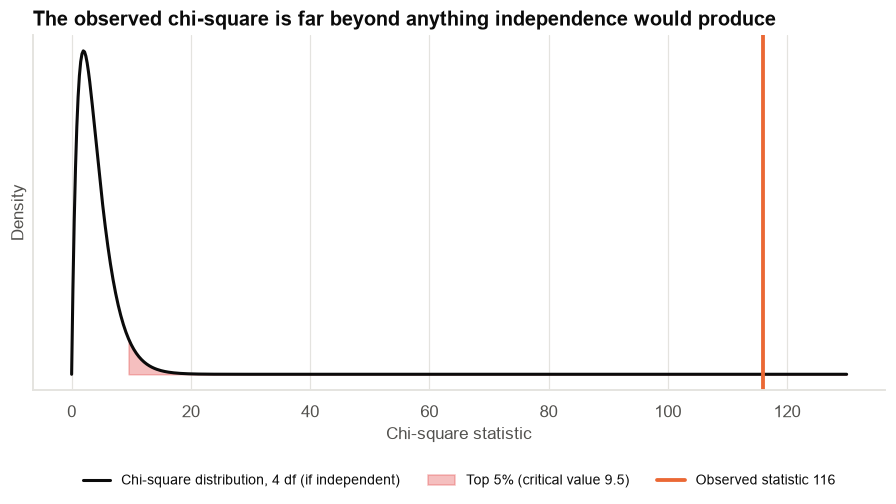

In [16]:
# Visualise the test: where does our statistic fall on the null distribution?
xs = np.linspace(0, 130, 600)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(xs, stats.chi2.pdf(xs, dof), color=INK, lw=2, label=f"Chi-square distribution, {dof} df (if independent)")
ax.fill_between(xs[xs >= crit_chi2], stats.chi2.pdf(xs[xs >= crit_chi2], dof), color=COLORS["red"], alpha=0.35,
                label=f"Top 5% (critical value {crit_chi2:.1f})")
ax.axvline(chi2_stat, color=HIGHLIGHT, lw=2.5, label=f"Observed statistic {chi2_stat:.0f}")
ax.set(title="The observed chi-square is far beyond anything independence would produce",
       xlabel="Chi-square statistic", ylabel="Density", yticks=[])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=9)
save_fig(fig, "fig03_chi_square_test", PATHS["figures"])
plt.show()

### 10.5 Effect size for the proposed ₹30k threshold: risk difference, risk ratio, odds ratio

In [17]:
a = int(loans.loc[low, "defaulted"].sum());  b = int((~loans.loc[low, "defaulted"].astype(bool)).sum())
c = int(loans.loc[~low, "defaulted"].sum()); d = int((~loans.loc[~low, "defaulted"].astype(bool)).sum())
t22 = Table2x2(np.array([[a, b], [c, d]]))
p1, p2 = a / (a + b), c / (c + d)
rd = p1 - p2
se_rd = np.sqrt(p1 * (1 - p1) / (a + b) + p2 * (1 - p2) / (c + d))
rd_ci = (rd - 1.96 * se_rd, rd + 1.96 * se_rd)

effects = pd.DataFrame({
    "estimate": [p1, p2, rd, t22.riskratio, t22.oddsratio],
    "ci_low": [proportion_ci(a, a + b)["lower"], proportion_ci(c, c + d)["lower"], rd_ci[0], *[t22.riskratio_confint()[0], t22.oddsratio_confint()[0]]],
    "ci_high": [proportion_ci(a, a + b)["upper"], proportion_ci(c, c + d)["upper"], rd_ci[1], *[t22.riskratio_confint()[1], t22.oddsratio_confint()[1]]],
}, index=["default rate, income < ₹30k", "default rate, income ≥ ₹30k", "risk difference (pp)", "risk ratio", "odds ratio"])
save_table(effects, "threshold_effects", PATHS["tables"])
print(f"2x2 table: below ₹30k {a} defaults / {a + b} loans;  ≥ ₹30k {c} defaults / {c + d} loans")
effects

2x2 table: below ₹30k 175 defaults / 1346 loans;  ≥ ₹30k 232 defaults / 4595 loans


,estimate,ci_low,ci_high
"default rate, income < ₹30k",0.130,0.113,0.149
"default rate, income ≥ ₹30k",0.050,0.045,0.057
risk difference (pp),0.080,0.060,0.099
risk ratio,2.575,2.137,3.103
odds ratio,2.810,2.286,3.455


- **Risk difference:** customers under ₹30k default about **8 percentage points** more often (13.0% vs 5.0%).
- **Risk ratio ≈ 2.6:** they are about two and a half times as likely to default (95% CI ≈ 2.1–3.1).
- **Odds ratio ≈ 2.8:** the odds of default (default : repay) are 2.8 times higher. The odds ratio is close to
  the risk ratio because default is fairly rare. They diverge as outcomes become common, which is a classic
  source of exaggerated headlines. Odds ratios matter because logistic regression reports them (Case 11).

**Report the absolute and the relative effect together.** "2.6× riskier" sounds dramatic. "13% vs 5%" says
that 87% of the riskier group still repays. Both are needed for a sound decision.

### 10.6 From evidence to decision: is a ₹30,000 floor worth it?

The statistics so far say low earners default more, and that this is not chance. They **do not** yet say the
floor is a good idea. To decide, we compare what the floor saves with what it costs:

- **Saved:** credit losses on defaulters who would no longer be approved. Loss on a defaulted unsecured loan
  ≈ **65%** of the loan amount (loss given default, LGD).
- **Lost:** lifetime profit on good customers who would no longer be approved. Net margin on a performing loan
  ≈ **12%** of the loan amount over its life (interest minus funding and operating cost).

These two parameters come from Finance and are **assumptions**, so we test sensitivity to them.

> **Key simplification.** We apply the floor retrospectively to loans we already approved and assume
> nothing else changes: the excluded customers would simply not have borrowed, and the remaining book would perform
> the same. We cannot observe applicants below ₹20k, so we cannot evaluate *lowering* the floor.

In [18]:
LGD, MARGIN = 0.65, 0.12

def floor_impact(df, floor, lgd=LGD, margin=MARGIN):
    ex = df[df["monthly_income"] < floor]
    saved = (lgd * ex["loan_amount"] * ex["defaulted"]).sum()
    lost = (margin * ex["loan_amount"] * (1 - ex["defaulted"])).sum()
    return {"floor": floor, "share_excluded": len(ex) / len(df), "loans_excluded": len(ex),
            "defaults_avoided": int(ex["defaulted"].sum()), "good_customers_lost": int((1 - ex["defaulted"]).sum()),
            "default_rate_excluded": ex["defaulted"].mean() if len(ex) else np.nan,
            "default_rate_remaining": df.loc[df["monthly_income"] >= floor, "defaulted"].mean(),
            "losses_avoided_cr": saved / 1e7, "margin_lost_cr": lost / 1e7, "net_value_cr": (saved - lost) / 1e7}

floors = [22_500, 25_000, 27_500, 30_000, 32_500, 35_000, 40_000]
impact = pd.DataFrame([floor_impact(loans, f) for f in floors]).set_index("floor")
impact["good_lost_per_default_avoided"] = impact["good_customers_lost"] / impact["defaults_avoided"]
save_table(impact, "floor_impact", PATHS["tables"])
impact

,share_excluded,loans_excluded,defaults_avoided,good_customers_lost,default_rate_excluded,default_rate_remaining,losses_avoided_cr,margin_lost_cr,net_value_cr,good_lost_per_default_avoided
floor,,,,,,,,,,
22500,0.066,390,52,338,0.133,0.064,0.276,0.338,-0.063,6.500
25000,0.127,756,104,652,0.138,0.058,0.616,0.709,-0.093,6.269
27500,0.177,1051,142,909,0.135,0.054,0.831,1.018,-0.187,6.401
30000,0.227,1346,175,1171,0.130,0.050,1.099,1.387,-0.289,6.691
32500,0.275,1631,200,1431,0.123,0.048,1.298,1.803,-0.505,7.155
35000,0.317,1882,221,1661,0.117,0.046,1.511,2.169,-0.658,7.516
40000,0.400,2375,251,2124,0.106,0.044,1.806,2.994,-1.188,8.462


In [19]:
# Uncertainty: bootstrap the 6,000-loan file to get a CI for the net value of the ₹30k floor.
idx = np.arange(len(loans))
boot_net = []
for _ in range(2_000):
    sample = loans.iloc[rng.choice(idx, len(idx), replace=True)]
    boot_net.append(floor_impact(sample, PROPOSED_FLOOR)["net_value_cr"])
boot_net = np.array(boot_net)
net30 = impact.loc[PROPOSED_FLOOR, "net_value_cr"]
net_ci = np.quantile(boot_net, [0.025, 0.975])
print(f"Net value of the ₹30k floor on this cohort: ₹{net30:.2f} crore, 95% bootstrap CI [₹{net_ci[0]:.2f}, ₹{net_ci[1]:.2f}] crore")
print(f"Share of bootstrap samples in which the floor creates value: {(boot_net > 0).mean():.1%}")

# Break-even margin: the margin at which saved losses exactly equal lost profit.
ex30 = loans[loans["monthly_income"] < PROPOSED_FLOOR]
breakeven_margin = LGD * (ex30["loan_amount"] * ex30["defaulted"]).sum() / (ex30["loan_amount"] * (1 - ex30["defaulted"])).sum()
print(f"Break-even lifetime margin (with LGD {LGD:.0%}): {breakeven_margin:.1%}. "
      f"The floor pays only if good loans earn less than this.")

# Sensitivity grid: net value (₹ crore) of the ₹30k floor across LGD and margin assumptions.
grid = pd.DataFrame({f"margin {m:.0%}": [floor_impact(loans, PROPOSED_FLOOR, lgd=l, margin=m)["net_value_cr"]
                                        for l in (0.45, 0.55, 0.65, 0.75, 0.85)] for m in (0.06, 0.09, 0.12, 0.15)},
                    index=[f"LGD {l:.0%}" for l in (0.45, 0.55, 0.65, 0.75, 0.85)])
save_table(grid, "floor_sensitivity", PATHS["tables"])
grid.style.format("₹{:.2f} cr").background_gradient(cmap="RdBu", vmin=-0.6, vmax=0.6)

Net value of the ₹30k floor on this cohort: ₹-0.29 crore, 95% bootstrap CI [₹-0.48, ₹-0.08] crore
Share of bootstrap samples in which the floor creates value: 0.4%
Break-even lifetime margin (with LGD 65%): 9.5%. The floor pays only if good loans earn less than this.


,margin 6%,margin 9%,margin 12%,margin 15%
LGD 45%,₹0.07 cr,₹-0.28 cr,₹-0.63 cr,₹-0.97 cr
LGD 55%,₹0.24 cr,₹-0.11 cr,₹-0.46 cr,₹-0.80 cr
LGD 65%,₹0.40 cr,₹0.06 cr,₹-0.29 cr,₹-0.64 cr
LGD 75%,₹0.57 cr,₹0.23 cr,₹-0.12 cr,₹-0.47 cr
LGD 85%,₹0.74 cr,₹0.40 cr,₹0.05 cr,₹-0.30 cr


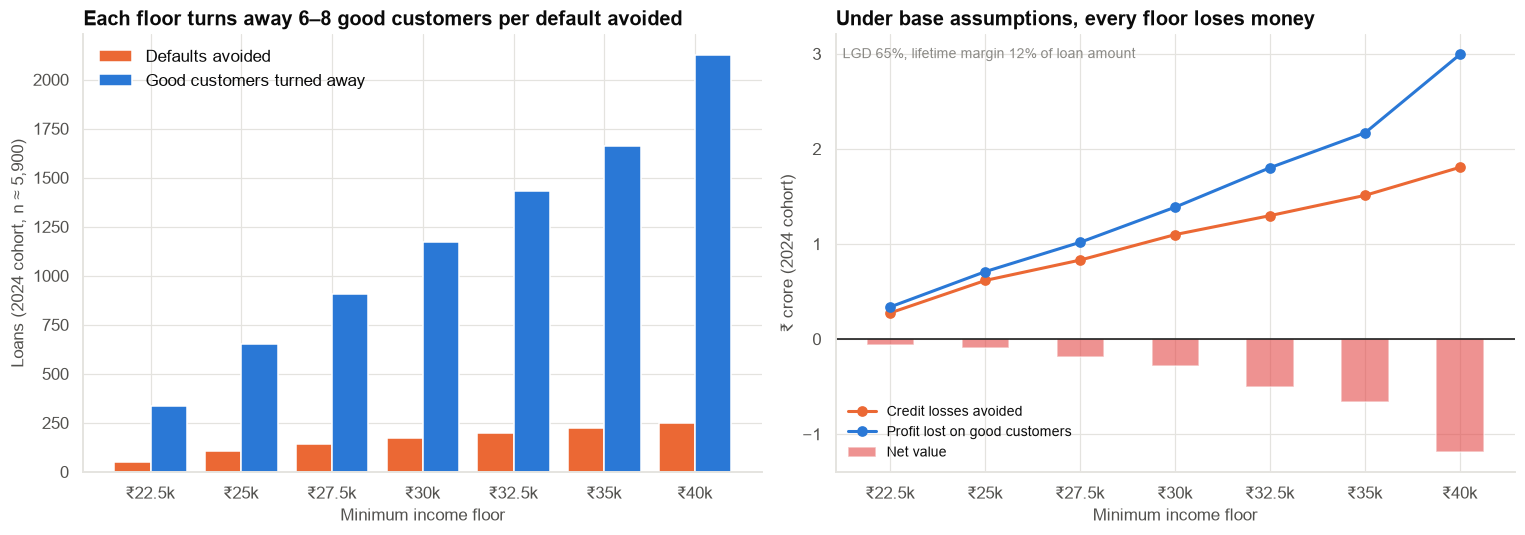

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
xs_f = np.arange(len(impact))
ax.bar(xs_f - 0.2, impact["defaults_avoided"], width=0.4, color=HIGHLIGHT, label="Defaults avoided")
ax.bar(xs_f + 0.2, impact["good_customers_lost"], width=0.4, color=PRIMARY, label="Good customers turned away")
ax.set_xticks(xs_f, [f"₹{f / 1000:g}k" for f in impact.index])
ax.set(title="Each floor turns away 6–8 good customers per default avoided",
       xlabel="Minimum income floor", ylabel="Loans (2024 cohort, n ≈ 5,900)")
ax.legend(loc="upper left")

ax = axes[1]
ax.plot(xs_f, impact["losses_avoided_cr"], marker="o", color=HIGHLIGHT, lw=2, label="Credit losses avoided")
ax.plot(xs_f, impact["margin_lost_cr"], marker="o", color=PRIMARY, lw=2, label="Profit lost on good customers")
ax.bar(xs_f, impact["net_value_cr"], color=[COLORS["red"] if v < 0 else COLORS["green"] for v in impact["net_value_cr"]],
       alpha=0.6, width=0.5, label="Net value")
ax.axhline(0, color=INK, lw=1)
ax.set_xticks(xs_f, [f"₹{f / 1000:g}k" for f in impact.index])
ax.set(title="Under base assumptions, every floor loses money", xlabel="Minimum income floor", ylabel="₹ crore (2024 cohort)")
ax.legend(loc="lower left", fontsize=9)
add_note(ax, f"LGD {LGD:.0%}, lifetime margin {MARGIN:.0%} of loan amount", "upper left")
fig.tight_layout()
save_fig(fig, "fig04_floor_tradeoff", PATHS["figures"])
plt.show()

**Observation.** The ₹30k floor would have excluded about 23% of the 2024 book: about 175 defaulters, but also
about 1,170 customers who repaid. That is roughly **7 good customers lost for every default avoided**.

**Interpretation.** Under base assumptions, the losses avoided (≈ ₹1.1 crore) are smaller than the profit forgone
(≈ ₹1.4 crore). The net is about **−₹0.3 crore** on this cohort, and negative in essentially every bootstrap
sample. The break-even lifetime margin is about 9.5%. The floor pays only if good loans earn less than that, or
if LGD is much higher than 65%.

**Business implication.** A risk ratio of 2.6 sounds like a strong case for the floor. It is not, because
**87% of the excluded customers are good customers**. The base rate dominates. This is the most important
lesson of the case.

**Caveat.** The conclusion depends on the LGD and margin assumptions (see the sensitivity grid). It ignores
second-order effects: competitors capturing excluded customers, cross-sell value, and regulatory or
financial-inclusion considerations. It also assumes the remaining book performs as before.

### 10.7 A warning sign: income travels with other risk factors

Spearman correlations:


,monthly_income,credit_score,dti
monthly_income,1.000,0.400,-0.380
credit_score,0.400,1.000,-0.160
dti,-0.380,-0.160,1.000


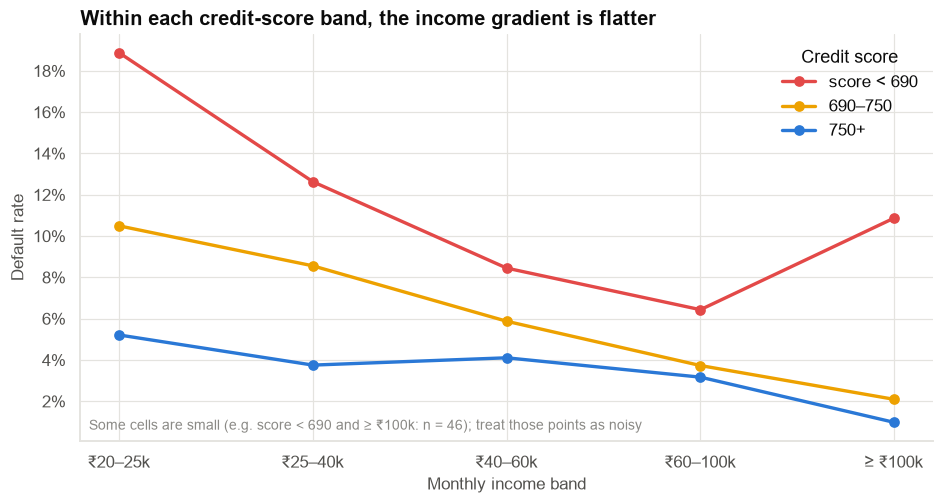

income_band,₹20–25k,₹25–40k,₹40–60k,₹60–100k,≥ ₹100k
score_band,,,,,
score < 690,355,586,367,171,46
690–750,305,713,681,590,239
750+,96,320,463,600,409


In [21]:
print("Spearman correlations:")
display(loans[["monthly_income", "credit_score", "dti"]].corr(method="spearman").round(2))

loans["score_band"] = pd.cut(loans["credit_score"], [0, 690, 750, 1000], labels=["score < 690", "690–750", "750+"])
strat = loans.pivot_table(index="score_band", columns="income_band", values="defaulted", aggfunc="mean", observed=True)
strat_n = loans.pivot_table(index="score_band", columns="income_band", values="defaulted", aggfunc="size", observed=True)
save_table(strat, "default_by_income_within_score", PATHS["tables"])

fig, ax = plt.subplots(figsize=(10, 4.8))
for (band, row), color in zip(strat.iterrows(), [COLORS["red"], COLORS["yellow"], COLORS["blue"]]):
    ax.plot(range(len(row)), row.values, marker="o", lw=2.2, color=color, label=band)
ax.set_xticks(range(len(strat.columns)), strat.columns)
ax.yaxis.set_major_locator(plt.MultipleLocator(0.02))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(title="Within each credit-score band, the income gradient is flatter",
       xlabel="Monthly income band", ylabel="Default rate")
ax.legend(title="Credit score", loc="upper right")
add_note(ax, f"Some cells are small (e.g. score < 690 and ≥ ₹100k: n = {strat_n.iloc[0, -1]}); treat those points as noisy", "lower left")
save_fig(fig, "fig05_income_within_score_band", PATHS["figures"])
plt.show()
strat_n

Income is positively correlated with credit score (ρ ≈ 0.40) and negatively with DTI (ρ ≈ −0.38). Lower
earners tend to have weaker credit histories and heavier debt burdens. When we look **within** credit-score bands,
default still tends to fall with income, but the gradient is noticeably flatter than in Figure 2. The top-right
point (low score, ≥ ₹100k) rests on only 46 loans and is noisy.

**What this means:** part of the "income effect" we measured is really a **credit-score and affordability effect**
that travels with income. The raw income comparison mixes them together. If the bank already uses score and DTI
in its decisions, an income floor would partly **double-count** risk it already prices. Separating these
effects properly needs a multivariable model (Cases 08, 11 and 27). For now this is a flag, not a conclusion.

## Section 11 — Results

In [22]:
results = pd.DataFrame([
    ["Mean income, defaulted − repaid (₹)", m1 - m2, ci_welch[0], ci_welch[1], f"Welch t = {t_welch:.1f}, df ≈ {df_welch:.0f}", p_welch, f"Cohen's d = {d_effect:.2f}"],
    ["Typical income ratio, defaulted / repaid", ratio, ratio_ci[0], ratio_ci[1], f"Welch t on logs = {log_test.statistic:.1f}", log_test.pvalue, f"{1 - ratio:.0%} lower"],
    ["Median income difference (₹)", inc_def.median() - inc_rep.median(), med_ci[0], med_ci[1], "bootstrap", np.nan, ""],
    ["P(defaulter earns more than repayer)", cles, np.nan, np.nan, f"Mann-Whitney U", mw.pvalue, f"rank-biserial = {rank_biserial:.2f}"],
    ["Income band × default", chi2_stat, np.nan, np.nan, f"chi-square, df = {dof}", p_chi2, f"Cramér's V = {cramers_v:.2f}"],
    ["Risk ratio, < ₹30k vs ≥ ₹30k", t22.riskratio, *t22.riskratio_confint(), "Wald CI (log scale)", np.nan, f"RD = {rd * 100:.1f} pp"],
    ["Net value of ₹30k floor (₹ crore)", net30, net_ci[0], net_ci[1], "bootstrap", np.nan, f"break-even margin {breakeven_margin:.1%}"],
], columns=["quantity", "estimate", "ci_low", "ci_high", "test / method", "p_value", "effect size"]).set_index("quantity")
save_table(results, "key_results", PATHS["tables"])
results.assign(p_value=results["p_value"].map(fmt_p))

,estimate,ci_low,ci_high,test / method,p_value,effect size
quantity,,,,,,
"Mean income, defaulted − repaid (₹)","-17,361.942","-19,937.693","-14,786.192","Welch t = -13.2, df ≈ 581",< 0.001,Cohen's d = -0.45
"Typical income ratio, defaulted / repaid",0.739,0.705,0.776,Welch t on logs = -12.3,< 0.001,26% lower
Median income difference (₹),"-14,800.000","-17,400.000","-12,400.000",bootstrap,n/a,
P(defaulter earns more than repayer),0.340,NaN,NaN,Mann-Whitney U,< 0.001,rank-biserial = -0.32
Income band × default,115.987,NaN,NaN,"chi-square, df = 4",< 0.001,Cramér's V = 0.14
"Risk ratio, < ₹30k vs ≥ ₹30k",2.575,2.137,3.103,Wald CI (log scale),n/a,RD = 8.0 pp
Net value of ₹30k floor (₹ crore),-0.289,-0.479,-0.078,bootstrap,n/a,break-even margin 9.5%


## Section 12 — Interpretation

**Income differs between defaulters and repayers, and it is not chance.** The average defaulter earned about
**₹17,000 a month less** than the average repayer (Welch 95% CI ≈ ₹14,800 – ₹19,900; t ≈ −13, p < 0.001). If the
true mean incomes were equal, a gap this large in samples of this size would essentially never occur. Because
raw means are inflated by a few high earners, the more relevant summary is the **typical** income:
defaulters' geometric-mean income is about **26% lower** (95% CI ≈ 22%–30%). On ranks, a randomly chosen
defaulter out-earns a randomly chosen repayer only **34%** of the time. The three methods target different
estimands and all point the same way, which makes the conclusion robust to the choice of method.

**Default depends on income band.** The chi-square test rejects independence (χ² ≈ 116, df = 4, p ≈ 10⁻²⁴), and
the trend test confirms a steady decline from about **13.8%** in the ₹20–25k band to about **2.0%** at ≥ ₹100k.
The association is **modest in strength** (Cramér's V ≈ 0.14). Income band explains only a small part of who
defaults.

**At the proposed ₹30k threshold:** default rates are 13.0% below vs 5.0% above, a risk difference of
about **8 percentage points** and a **risk ratio of about 2.6** (95% CI ≈ 2.1–3.1).

**And yet the floor is unlikely to pay.** 87% of the loans it would exclude were repaid. With an LGD of 65% and
a lifetime margin of 12%, the floor would have *reduced* value on the 2024 cohort by about **₹0.3 crore** (95%
bootstrap CI roughly −₹0.5 to −₹0.1 crore). It only becomes worthwhile if the lifetime margin on good loans is
below about 9.5%.

**Language check.** All of this is *association*. We have shown that lower income is associated with higher
default, not that low income *causes* default, and not that changing someone's income would change their risk.
Part of the association runs through credit score and DTI.

## Section 13 — What can we say?

### ✅ We can confidently say
- In the 2024 approved book, lower-income customers defaulted more often, with a steady decline across income
  bands (13.8% → 2.0%).
- Defaulters' typical income was about a quarter lower than repayers', and the gap is far too large to be
  sampling noise.
- 87% of customers under ₹30k repaid. P(default | low income) ≈ 13%, not the ≈ 43% implied by "43% of
  defaulters are low-income".

### 📊 We have evidence that
- A ₹30k floor would **reduce value** under Finance's base assumptions (LGD 65%, margin 12%). The result is
  **sensitive to the margin**: at a 9% margin, or with LGD near 85%, the floor roughly breaks even or pays.
- Part of the income–default association is shared with credit score and DTI.

### ❌ We cannot conclude
- That low income **causes** default, or that income is a better risk signal than score or DTI.
- Anything about applicants **below ₹20k**. They were never approved, so we have no performance data.
- That the floor's financial impact would be the same next year. It depends on application volumes and mix.

### 🔍 We would need additional analysis or data to conclude
- **A multivariable model** (logistic regression with income, score, DTI and employment) to measure income's
  *additional* predictive value (Cases 11 and 27).
- **Finance-validated LGD and margin by segment**, rather than book-wide averages.
- **A controlled test** (e.g., risk-based pricing or lower limits for low-income applicants in a pilot region)
  to measure the effect of an actual policy change (Case 04 / 21).

## Section 14 — Business interpretation

| Statistical finding | Data scientist interpretation | Business interpretation | Business action |
|---|---|---|---|
| Default rate 13.8% (₹20–25k) → 2.0% (≥ ₹100k); χ² p ≈ 10⁻²⁴, V ≈ 0.14 | Real, monotonic, modest-strength association | Income genuinely carries risk information | Keep income as an input to risk decisions |
| Risk ratio 2.6 (2.1–3.1) for < ₹30k; risk difference 8 pp | Strong relative effect, moderate absolute effect | Low earners are riskier, yet 87% of them repay | Don't let a relative risk alone drive an exclusion policy |
| P(low \| default) = 43% vs P(default \| low) = 13% | Inverse conditional probabilities | "Most defaulters are low-income" ≠ "most low-income customers default" | Correct the framing used in the policy paper |
| ₹30k floor: net ≈ −₹0.3 cr, break-even margin ≈ 9.5% | Expected value negative under base assumptions | The floor would cost more in lost good business than it saves | **Do not raise the floor**; consider pricing or limit-setting for low-income segments instead |
| Income gradient flatter within score bands | Income partly proxies score and DTI | A floor would double-count risk already captured | Build a multivariable model before adding any new income rule |

## Section 15 — Limitations

- **Selection (approved book only).** Performance is observed only for approved loans (income ≥ ₹20k, and other
  criteria). Default rates among *all* low-income applicants could differ. This is the "reject inference" problem
  in credit risk.
- **Confounding.** Income is correlated with credit score and DTI. Our estimates are total associations, not the
  effect of income alone.
- **Financial assumptions.** LGD (65%) and margin (12%) are book-wide averages from Finance. The sensitivity grid
  shows the conclusion flips if the true margin is about 9% or less, or if LGD is about 85% or more.
- **Static counterfactual.** We assume excluded customers simply disappear and nothing else changes.
- **Missing income** for 1% of loans (excluded). No sign of bias, but the comparison is imprecise.
- **One cohort, one year.** 2024 performance may not represent future economic conditions.
- **Synthetic data.**

## Section 16 — Final recommendation

**Do not raise the minimum income floor to ₹30,000 on the current evidence.** Lower-income customers do default
more, and the association is clear, consistent and not due to chance. But a hard floor would turn away about seven
good customers for every default it prevents, and under Finance's assumptions it would reduce value
(≈ −₹0.3 crore on the 2024 cohort; break-even margin ≈ 9.5%).

This recommendation is **conditional on the margin assumption**: if Finance confirms that good loans in the
₹20–30k segment earn a lifetime margin below about 9.5% of the loan amount, the case for the floor should be
re-examined.

Instead:
1. **Use income in a risk-based way.** Adjust pricing, loan size or tenure for lower-income segments rather than
   excluding them outright.
2. **Commission a multivariable risk model** to measure what income adds beyond credit score and DTI.
3. **Correct the framing in the policy paper:** "43% of defaulters are low-income" does not mean low-income
   customers are likely to default.

## Section 17 — What would I do next?

- Logistic regression of default on income, score, DTI, employment and city tier (Cases 11, 27).
- Ask Finance for LGD and margin **by income band**. Small loans may have a different margin structure.
- Evaluate **risk-based pricing** for the ₹20–30k segment: the price increase that would offset its extra
  expected loss.
- If the business still wants a policy change, **pilot it** in a few regions with a control group (Case 04).

---

### Concepts covered
Joint, marginal and conditional probability · independence · confusion of the inverse · Bayes' theorem (preview)
· contingency tables · Student's vs Welch's t-test · Welch-Satterthwaite df · Levene / Brown-Forsythe test ·
t-test on logs and ratio of geometric means · Mann-Whitney U and its estimand · common-language effect size ·
rank-biserial correlation · bootstrap CI for a difference in medians · chi-square test of independence · expected
counts · standardised residuals · chi-square distribution · Cramér's V · trend test for ordered categories · risk
difference · risk ratio · odds ratio · confirmatory vs exploratory analysis · statistical evidence vs policy value ·
sensitivity analysis · selection bias (approved population) · confounding (preview).

### Exercises
1. Run Student's t on the **logs** of income. Does the equal-variance problem persist on the log scale? Why or
   why not?
2. Repeat the chi-square test using only three bands (< ₹30k, ₹30–60k, ≥ ₹60k). How do χ², df and V change?
3. Find the LGD at which the ₹30k floor breaks even when the margin is 12%.
4. Within the "750+" score band only, compute the risk ratio for < ₹30k vs ≥ ₹30k. Compare it with the overall 2.6
   and explain the difference.